# DAR ES SALAAM INSTITUTE OF TECHNOLOGY
## DIGITAL SIGNAL PROCESSING LABORATORY

### WEEK 1 – LAB 0
### Task 1.1: Generating Elementary Discrete-Time Signals

**Module Code:** COU 07506

**Student Name:** Gwamaka A Mwakabuta

**Registration Number:** 240242462281

**Academic Year:** 2026/2027

**Experiment:** Unit Impulse, Unit Step, Unit Ramp and Exponential Signals

In [15]:
# Import numerical computing library
import numpy as np

# Import plotting library
import matplotlib.pyplot as plt

# Import signal processing functions
from scipy import signal

# Import WAV audio file functions
from scipy.io import wavfile

# Configure graph dimensions
plt.rcParams["figure.figsize"] = (9, 3.5)

print("Digital Signal Processing Environment Ready!")

Digital Signal Processing Environment Ready!


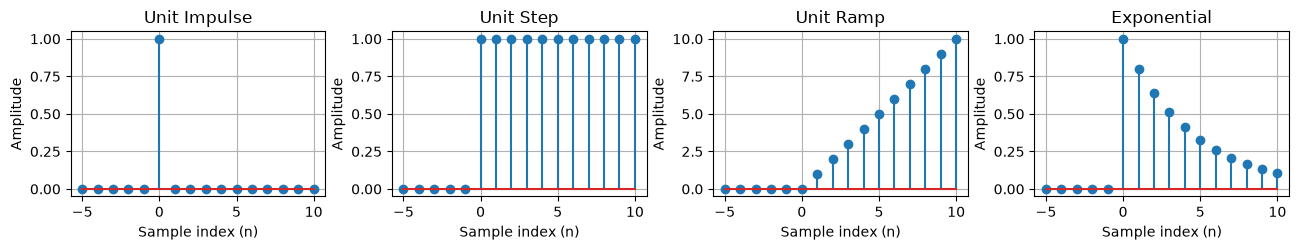

In [16]:
# ==========================================
# WEEK 1 - TASK 1.1
# Generating Elementary Discrete-Time Signals
# ==========================================

# Step 1: Create the discrete-time index
n = np.arange(-5, 11)

# Step 2: Generate the four elementary signals

# 1. Unit Impulse
delta = (n == 0).astype(float)

# 2. Unit Step
step = (n >= 0).astype(float)

# 3. Unit Ramp
ramp = n * step

# 4. Exponential Signal
expo = 0.8**n * step


# Step 3: Create four plotting areas
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))

# Step 4: Plot each signal
for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["Unit Impulse", "Unit Step", "Unit Ramp", "Exponential"]
):
    ax.stem(n, x)
    ax.set_title(title)
    ax.set_xlabel("Sample index (n)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

# Step 5: Display the graphs
plt.tight_layout()
plt.show()

In [17]:
# Verify selected sample values

print(" n | Impulse | Step | Ramp | Exponential")
print("--------------------------------------------")

for i, d, s, r, e in zip(n, delta, step, ramp, expo):
    if i in [-2, -1, 0, 1, 2, 3, 10]:
        print(f"{i:2d} | {d:7.2f} | {s:4.2f} | {r:4.2f} | {e:11.6f}")

 n | Impulse | Step | Ramp | Exponential
--------------------------------------------
-2 |    0.00 | 0.00 | -0.00 |    0.000000
-1 |    0.00 | 0.00 | -0.00 |    0.000000
 0 |    1.00 | 1.00 | 0.00 |    1.000000
 1 |    0.00 | 1.00 | 1.00 |    0.800000
 2 |    0.00 | 1.00 | 2.00 |    0.640000
 3 |    0.00 | 1.00 | 3.00 |    0.512000
10 |    0.00 | 1.00 | 10.00 |    0.107374


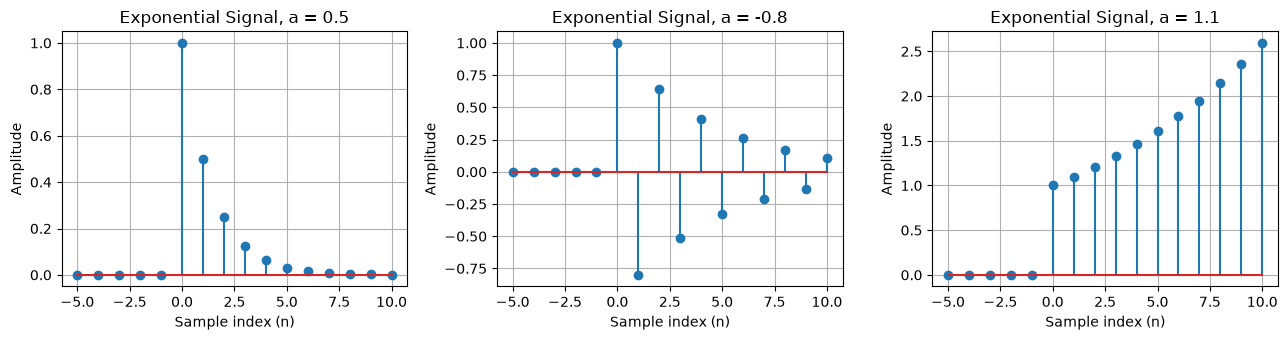

In [18]:
# ==========================================
# WEEK 1 - TASK 1.2 (PART A)
# Investigating Exponential Signals
# ==========================================

# Define the three values of a
a_values = [0.5, -0.8, 1.1]

# Create three plotting areas
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

# Generate and plot each exponential signal
for ax, a in zip(axes, a_values):

    x = (a ** n) * step

    ax.stem(n, x)
    ax.set_title(f"Exponential Signal, a = {a}")
    ax.set_xlabel("Sample index (n)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()

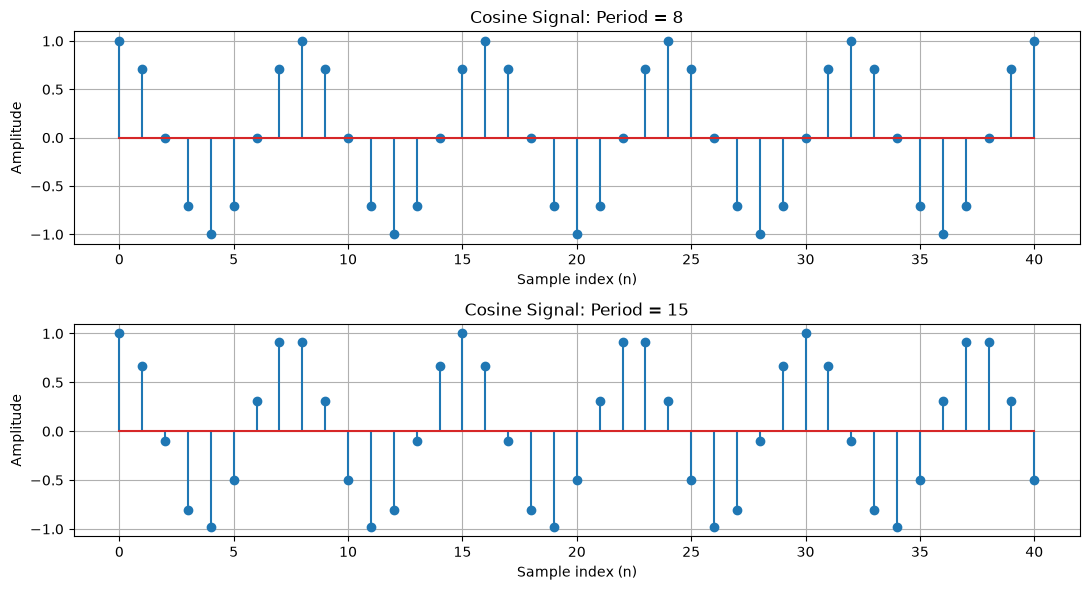

In [19]:
# ==========================================
# WEEK 1 - TASK 1.2 (PART B)
# Investigating Periodic Discrete-Time Signals
# ==========================================

# Generate sample indices from 0 to 40
n_periodic = np.arange(0, 41)

# Generate the two cosine signals
x1 = np.cos(2 * np.pi * n_periodic / 8)

x2 = np.cos(2 * np.pi * n_periodic / 7.5)

# Create two plotting areas
fig, axes = plt.subplots(2, 1, figsize=(11, 6))

# Plot first signal
axes[0].stem(n_periodic, x1)
axes[0].set_title("Cosine Signal: Period = 8")
axes[0].set_xlabel("Sample index (n)")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

# Plot second signal
axes[1].stem(n_periodic, x2)
axes[1].set_title("Cosine Signal: Period = 15")
axes[1].set_xlabel("Sample index (n)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [20]:
# Verify periodicity numerically

print("First signal:")
print("x1[0] =", x1[0])
print("x1[8] =", x1[8])

print("\nSecond signal:")
print("x2[0] =", x2[0])
print("x2[15] =", x2[15])

print("\nPeriodicity verification:")
print("First signal repeats after 8 samples:",
      np.allclose(x1[:-8], x1[8:]))

print("Second signal repeats after 15 samples:",
      np.allclose(x2[:-15], x2[15:]))

First signal:
x1[0] = 1.0
x1[8] = 1.0

Second signal:
x2[0] = 1.0
x2[15] = 1.0

Periodicity verification:
First signal repeats after 8 samples: True
Second signal repeats after 15 samples: True


## Task 1.3 – Working with Audio

### Recording, Loading and Analysing My Voice

Sampling Frequency: 48000 Hz
Duration: 4.85 seconds
Number of Samples: 232799


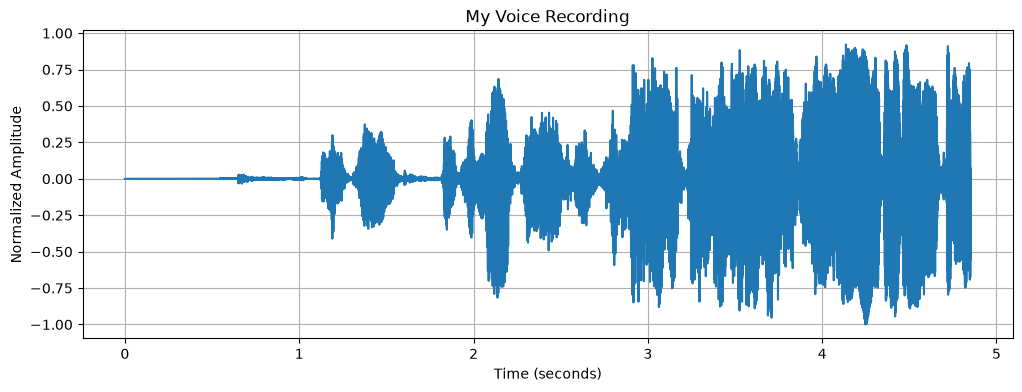

In [21]:
# ==========================================
# WEEK 1 - TASK 1.3
# Working with Audio
# ==========================================

from pathlib import Path

# Locate the audio recording
candidates = [
    Path("Week-01") / "my_voice.wav",
    Path("my_voice.wav")
]

fname = next((p for p in candidates if p.exists()), None)

if fname is None:
    raise FileNotFoundError("my_voice.wav not found.")

# Read the WAV file
fs, x = wavfile.read(str(fname))

# Convert audio to floating-point numbers
x = np.asarray(x, dtype=float)

# Convert stereo to mono if necessary
if x.ndim > 1:
    x = x.mean(axis=1)

# Normalize audio
peak = np.max(np.abs(x))

if peak == 0:
    raise ValueError("Audio recording is silent.")

x = x / peak

# Calculate time axis
t = np.arange(len(x)) / fs

# Display recording information
print("Sampling Frequency:", fs, "Hz")
print("Duration:", round(len(x) / fs, 2), "seconds")
print("Number of Samples:", len(x))

# Plot the waveform
plt.figure(figsize=(12, 4))
plt.plot(t, x)

plt.title("My Voice Recording")
plt.xlabel("Time (seconds)")
plt.ylabel("Normalized Amplitude")
plt.grid(True)
plt.show()

In [1]:
from pathlib import Path

# Check the current working directory
print("Current directory:", Path.cwd())

# Locate the audio recording
audio_file = Path("my_voice.wav")

print("Resolved path:", audio_file.resolve())
print("File exists:", audio_file.exists())

if audio_file.exists():

    print("File size:", audio_file.stat().st_size, "bytes")

    # Inspect WAV header
    with open(audio_file, "rb") as f:
        header = f.read(16)

    print("File header:", header)

else:
    print("Audio file not found!")

Current directory: c:\Users\Gwamaka Mwakabuta\Desktop\3 year\DSP\COU07506-DSP-Labs\Week-01
Resolved path: C:\Users\Gwamaka Mwakabuta\Desktop\3 year\DSP\COU07506-DSP-Labs\Week-01\my_voice.wav
File exists: True
File size: 465642 bytes
File header: b'RIFF\xe2\x1a\x07\x00WAVEfmt '


In [23]:
from IPython.display import Audio, display

display(Audio(x, rate=fs))

## Week 1 – Analysis Questions

### Question 1
What is the sampling rate of your phone's recording?
How many numbers are needed to store one minute of it in mono?

**Answer:**

The sampling frequency of my voice recording is 48,000 Hz.

The number of samples required for one minute of mono audio is:

N = Sampling Frequency × Duration

N = 48,000 × 60

N = 2,880,000 samples.

Therefore, 2,880,000 numerical samples are required.

### Question 2
Why is a stem plot more appropriate than a continuous
line for x(n)?

**Answer:**

A stem plot is more appropriate because a discrete-time
signal is defined at individual integer sample positions.
It displays each sample independently without implying
that values exist between the sample positions.

### Question 3
For a = 1.1 the exponential grows. Which property of
a system would such a signal violate if it were an
impulse response?

**Answer:**

It would violate Bounded-Input Bounded-Output (BIBO)
stability.

For a discrete-time LTI system to be stable, its impulse
response must be absolutely summable.

Since the exponential sequence (1.1)^n grows without
bound, its absolute sum diverges. Therefore, the system
would be unstable.

## AI-Use Statement

**AI tools used:** ChatGPT (OpenAI).

**Used for:**
- Understanding Digital Signal Processing concepts.
- Explaining mathematical formulas and theoretical concepts.
- Suggesting and explaining Python code for Tasks 1.1–1.3.
- Troubleshooting programming errors.
- Interpreting experimental results and graphs.

**How I verified the output:**

I executed the suggested code using Python 3.11.9,
NumPy, SciPy and Matplotlib in VS Code/Jupyter.

I verified the generated signals against their
mathematical definitions, checked numerical values,
tested periodicity and successfully loaded and
analysed my WAV audio recording.

**Declaration:**

I confirm that I understand and can explain all
submitted code.

## Pre-lab Preparation

### Question: List three devices that contain DSP
and identify one signal processed by each.

**1. Smartphone**
- Signal processed: Voice/audio signal.
- Application: Speech recording, noise reduction and audio playback.

**2. Laptop**
- Signal processed: Digital audio signal.
- Application: Audio playback, recording and sound processing.

**3. Smartwatch**
- Signal processed: Accelerometer or optical heart-rate sensor signal.
- Application: Physical activity monitoring and heart-rate measurement.